# Experiment 4 — Multilingual and Cross-Language Scam Detection

**Runs in Google Colab with a free GPU; no paid APIs.**

This notebook compares:
1. English-only TF-IDF + Logistic Regression.
2. A multilingual pretrained transformer fine-tuned on English-only training data.
3. The same multilingual transformer fine-tuned on English plus translated Hindi training examples (augmentation).

It evaluates English, Hindi, and optionally Hinglish. All variants of a source message must share a group ID and stay in the same split to prevent translation leakage.

**Research limitation:** the multilingual SMS collection was machine-translated from an English SMS dataset. Results on its Hindi column measure robustness to translated text, not real-world Hindi scam detection. The optional Hinglish dataset is small in its hand-written Hinglish subset and must be reported as exploratory only. Do not claim generalization to naturally occurring messages from these data alone.


## 1. Enable a free GPU
In Colab, choose **Runtime → Change runtime type → T4 GPU** if available. Then run the cells in order. CPU will work for the TF-IDF baseline, but transformer fine-tuning will be slower.

## 2. Install packages

In [1]:
!pip -q install -U datasets transformers accelerate scikit-learn pandas matplotlib seaborn pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-c

## 3. Imports and settings

In [2]:
import os, re, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, Dataset, DatasetDict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU)")
os.makedirs("experiment4_results", exist_ok=True)

# Change only if the model is unavailable in your runtime.
MULTILINGUAL_MODEL = "bert-base-multilingual-cased"
MAX_LENGTH = 128
EPOCHS = 2
BATCH_SIZE = 16 if torch.cuda.is_available() else 4


GPU: Tesla T4


## 4. Download and inspect the multilingual SMS dataset

The loader first tries the Hugging Face dataset repository. If the repository loader fails, it prints the exact error rather than silently switching datasets. Inspect the displayed columns before continuing.

In [3]:
MULTILINGUAL_REPO = "dbarbedillo/SMS_Spam_Multilingual_Collection_Dataset"

raw = load_dataset(MULTILINGUAL_REPO)
print(raw)
for split_name, split_ds in raw.items():
    print("\\nSPLIT:", split_name)
    print("COLUMNS:", split_ds.column_names)
    print("EXAMPLE:", split_ds[0])
    break


README.md:   0%|          | 0.00/1.32k [00:00<?, ?B/s]

data-augmented.csv: reconstructing file:   0%|          |  0.00B / 14.2MB            

data-augmented.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5572 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no'],
        num_rows: 5572
    })
})
\nSPLIT: train
COLUMNS: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no']
EXAMPLE: {'Unnamed: 0': 0, 'labels': 'ham', 'text': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...', 'text_hi': 'Dakag बिंदु तक जाओ, पागल. केवल Bag Non महान विश्व cag में उपलब्ध है... वहाँ एक अधिक wack मिला...', 'text_de': 'Gehen Sie bis jurong Punkt, verrückt.. Verfügbar nur in buggis n great world la e buffet... C

## 5. Convert dataset to a standard long format

The code below supports common **long format** (one row per language) and **wide format** (separate columns per language). It tries to identify text, label, and language fields. If automatic detection fails, edit the three configuration values at the top of the cell to match the printed columns.

The `group_id` is essential: translated versions of one original message must not be divided between training and testing.

In [5]:
# --- Adjust these only if the previous cell shows different column names ---
TEXT_COL = None       # e.g. "text"
LABEL_COL = "labels"  # e.g. "label"
LANG_COL = None       # e.g. "language" for long format
GROUP_COL = None      # e.g. "id" if provided
# For wide-format data, set LANG_TEXT_COLS explicitly if needed, e.g.
LANG_TEXT_COLS = {"en": "text", "hi": "text_hi"}

def to_pandas_dataset(ds_dict):
    frames = []
    for split_name, ds in ds_dict.items():
        part = ds.to_pandas()
        part["_source_split"] = split_name
        frames.append(part)
    return pd.concat(frames, ignore_index=True)

raw_df = to_pandas_dataset(raw)
print("Raw shape:", raw_df.shape)
print("Columns:", list(raw_df.columns))

def find_col(cols, candidates):
    low = {str(c).lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    for c in cols:
        if any(k in str(c).lower() for k in candidates):
            return c
    return None

if TEXT_COL is None and LANG_TEXT_COLS is None:
    TEXT_COL = find_col(raw_df.columns, ["text", "message", "sms", "sentence", "content"])
if LABEL_COL is None:
    LABEL_COL = find_col(raw_df.columns, ["label", "category", "target", "class", "type"])
if LANG_COL is None and LANG_TEXT_COLS is None:
    LANG_COL = find_col(raw_df.columns, ["language", "lang", "locale"])
if GROUP_COL is None:
    GROUP_COL = find_col(raw_df.columns, ["source_id", "original_id", "group_id", "message_id", "id"])

print("Detected:", {"text": TEXT_COL, "label": LABEL_COL, "language": LANG_COL, "group": GROUP_COL})

LANG_ALIASES = {
    "en":"en", "english":"en", "eng":"en",
    "hi":"hi", "hindi":"hi",
    "hinglish":"hinglish", "hi-latn":"hinglish", "romanized hindi":"hinglish",
    "hindi english":"hinglish", "mixed":"hinglish", "code-mixed":"hinglish"
}

def norm_lang(x):
    s = str(x).strip().lower().replace("_", "-")
    return LANG_ALIASES.get(s, s)

def norm_label(x):
    s = str(x).strip().lower()
    if s in {"spam","scam","fraud","1","true","yes"}: return 1
    if s in {"ham","legitimate","benign","safe","0","false","no"}: return 0
    try:
        n = int(float(s))
        if n in (0,1): return n
    except Exception:
        pass
    return np.nan

# Handle wide-format mapping if configured
if LANG_TEXT_COLS is not None and LABEL_COL is not None:
    parts = []
    for lang, col in LANG_TEXT_COLS.items():
        if col in raw_df.columns:
            tmp = raw_df[[col, LABEL_COL]].copy()
            tmp.columns = ["text", "label"]
            tmp["language"] = lang
            # Create a stable group_id based on the original row index
            tmp["group_id"] = raw_df.index.astype(str)
            parts.append(tmp)
    data = pd.concat(parts, ignore_index=True)
else:
    if TEXT_COL is None or LABEL_COL is None:
        raise ValueError("Could not detect text/label/language columns. Use printed columns to set TEXT_COL, LABEL_COL, LANG_COL or LANG_TEXT_COLS, then rerun this cell.")
    if LANG_COL is None:
        raise ValueError("Text and label were detected but language column was not. Inspect columns and set LANG_COL manually.")
    data = raw_df[[TEXT_COL, LABEL_COL, LANG_COL] + ([GROUP_COL] if GROUP_COL else [])].copy()
    data.columns = ["text", "label", "language"] + (["group_id"] if GROUP_COL else [])
    if "group_id" not in data:
        raise ValueError("No source/group ID detected. Do not randomly split translations. Set GROUP_COL to the original-message ID column.")
    data["language"] = data["language"].map(norm_lang)

data["text"] = data["text"].astype(str).str.strip()
data["label"] = data["label"].map(norm_label)
data = data.dropna(subset=["text","label","language","group_id"])
data["label"] = data["label"].astype(int)
data = data[data["text"].str.len() > 0].copy()
data["group_id"] = data["group_id"].astype(str)

# Keep only languages requested and present.
data = data[data["language"].isin(["en","hi","hinglish"])].copy()
print("Clean shape:", data.shape)
display(data.groupby(["language","label"]).size().rename("count").reset_index())
display(data.head())
data.to_csv("experiment4_results/standardized_multilingual_data.csv", index=False)

Raw shape: (5572, 24)
Columns: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no', '_source_split']
Detected: {'text': None, 'label': 'labels', 'language': None, 'group': 'text_id'}
Clean shape: (11144, 4)


,language,label,count
0,en,0,4825
1,en,1,747
2,hi,0,4825
3,hi,1,747


,text,label,language,group_id
0,"Go until jurong point, crazy.. Available only ...",0,en,0
1,Ok lar... Joking wif u oni...,0,en,1
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,en,2
3,U dun say so early hor... U c already then say...,0,en,3
4,"Nah I don't think he goes to usf, he lives aro...",0,en,4


## 6. Create a leakage-safe group split

This splits by original-message group ID, not individual translated row. If the dataset has no source ID or original-message alignment, stop and fix the schema rather than claiming leakage-safe evaluation.

In [6]:
groups = data["group_id"].drop_duplicates().to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_group_idx, test_group_idx = next(gss.split(groups, groups=groups))
train_groups = set(groups[train_group_idx])
test_groups = set(groups[test_group_idx])

train_df = data[data["group_id"].isin(train_groups)].copy()
test_df = data[data["group_id"].isin(test_groups)].copy()
assert set(train_df.group_id).isdisjoint(set(test_df.group_id))
print("Train rows:", len(train_df), "Test rows:", len(test_df))
print("Train groups:", train_df.group_id.nunique(), "Test groups:", test_df.group_id.nunique())
display(pd.crosstab(train_df.language, train_df.label))
display(pd.crosstab(test_df.language, test_df.label))


Train rows: 8914 Test rows: 2230
Train groups: 4457 Test groups: 1115


label,0,1
language,,
en,3851,606
hi,3851,606


label,0,1
language,,
en,974,141
hi,974,141


## 7. Model 1 — English-only TF-IDF baseline

This model trains on English training messages only. It is then evaluated on English, Hindi, and Hinglish held-out rows. Hindi/Hinglish scores are cross-language transfer results.

In [7]:
en_train = train_df[train_df.language == "en"].copy()
if en_train["label"].nunique() < 2:
    raise ValueError("English training data must contain both labels.")
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=150000, strip_accents=None)),
    ("clf", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED))
])
tfidf_model.fit(en_train.text, en_train.label)

def metric_row(model_name, language, y_true, y_pred):
    return {
        "model": model_name,
        "language": language,
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "scam_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "scam_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "false_positive_rate": (
            ((np.array(y_true)==0) & (np.array(y_pred)==1)).sum() /
            max(1, (np.array(y_true)==0).sum())
        )
    }

all_results = []
predictions = []
for lang in ["en","hi","hinglish"]:
    part = test_df[test_df.language == lang]
    if len(part) == 0:
        print("Skipping absent language:", lang); continue
    pred = tfidf_model.predict(part.text)
    all_results.append(metric_row("english_tfidf", lang, part.label, pred))
    predictions.extend([{"model":"english_tfidf","language":lang,"group_id":g,"text":t,"y_true":int(y),"y_pred":int(p)}
                        for g,t,y,p in zip(part.group_id, part.text, part.label, pred)])
    print("\\nTF-IDF:", lang)
    print(classification_report(part.label, pred, labels=[0,1], target_names=["legitimate","scam"], zero_division=0))


\nTF-IDF: en
              precision    recall  f1-score   support

  legitimate       0.99      0.99      0.99       974
        scam       0.95      0.96      0.95       141

    accuracy                           0.99      1115
   macro avg       0.97      0.98      0.97      1115
weighted avg       0.99      0.99      0.99      1115

\nTF-IDF: hi
              precision    recall  f1-score   support

  legitimate       0.90      1.00      0.95       974
        scam       0.97      0.26      0.41       141

    accuracy                           0.91      1115
   macro avg       0.94      0.63      0.68      1115
weighted avg       0.91      0.91      0.88      1115

Skipping absent language: hinglish


## 8. Prepare transformer datasets

We use `bert-base-multilingual-cased`, a multilingual pretrained model that supports Hindi and English. The English-only version sees only English training messages. The augmented version sees English plus the Hindi translations of those same training groups. No held-out group is added to training.

If the dataset has no Hindi data, this notebook will stop rather than fabricate results.

In [8]:
if not (train_df.language == "en").any() or not (test_df.language == "hi").any():
    raise ValueError("Need English training rows and Hindi test rows to run the cross-language experiment.")

id2label = {0:"legitimate", 1:"scam"}
label2id = {"legitimate":0, "scam":1}

def train_transformer(train_texts, train_labels, run_name):
    tokenizer = AutoTokenizer.from_pretrained(MULTILINGUAL_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        MULTILINGUAL_MODEL, num_labels=2, id2label=id2label, label2id=label2id
    )
    train_enc = tokenizer(list(train_texts), truncation=True, max_length=MAX_LENGTH)
    train_ds = Dataset.from_dict({
        "input_ids": train_enc["input_ids"],
        "attention_mask": train_enc["attention_mask"],
        "labels": list(map(int, train_labels))
    })
    args = TrainingArguments(
        output_dir=f"experiment4_results/{run_name}",
        num_train_epochs=EPOCHS,
        learning_rate=2e-5,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        weight_decay=0.01,
        logging_steps=50,
        save_strategy="no",
        report_to="none",
        seed=SEED,
        fp16=torch.cuda.is_available(),
        dataloader_num_workers=2
    )
    trainer = Trainer(
        model=model, args=args, train_dataset=train_ds,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer)
    )
    trainer.train()
    return trainer, tokenizer

def eval_transformer(trainer, tokenizer, model_name):
    for lang in ["en","hi","hinglish"]:
        part = test_df[test_df.language == lang]
        if len(part) == 0:
            continue
        enc = tokenizer(part.text.tolist(), truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt")
        device = trainer.model.device
        enc = {k:v.to(device) for k,v in enc.items()}
        trainer.model.eval()
        with torch.no_grad():
            logits = trainer.model(**enc).logits
        pred = logits.argmax(dim=1).cpu().numpy()
        all_results.append(metric_row(model_name, lang, part.label.to_numpy(), pred))
        predictions.extend([{"model":model_name,"language":lang,"group_id":g,"text":t,"y_true":int(y),"y_pred":int(p)}
                            for g,t,y,p in zip(part.group_id, part.text, part.label, pred)])
        print(f"\\n{model_name}: {lang}")
        print(classification_report(part.label, pred, labels=[0,1], target_names=["legitimate","scam"], zero_division=0))

# Model 2: multilingual transformer trained on English only
m2_train = train_df[train_df.language == "en"].copy()
trainer_en, tokenizer_en = train_transformer(m2_train.text, m2_train.label, "multilingual_english_only")
eval_transformer(trainer_en, tokenizer_en, "multilingual_english_only")


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.172647
100,0.098760
150,0.048723
200,0.039079
250,0.064457
300,0.072386
350,0.036812
400,0.031232
450,0.035804
500,0.039898


\nmultilingual_english_only: en
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00       974
        scam       0.98      0.97      0.98       141

    accuracy                           0.99      1115
   macro avg       0.99      0.98      0.99      1115
weighted avg       0.99      0.99      0.99      1115

\nmultilingual_english_only: hi
              precision    recall  f1-score   support

  legitimate       0.98      0.99      0.98       974
        scam       0.92      0.85      0.88       141

    accuracy                           0.97      1115
   macro avg       0.95      0.92      0.93      1115
weighted avg       0.97      0.97      0.97      1115



## 9. Model 3 — Multilingual transformer with translation-based augmentation

Augmentation adds Hindi training translations only from the training groups. This is intentionally a controlled translated-data augmentation condition. It is not evidence that translation augmentation will work equally well on natural Hindi messages.

In [9]:
# Use English + Hindi rows from training groups only. If many translations are duplicated,
# deduplicate identical text while retaining the label.
aug_train = train_df[train_df.language.isin(["en","hi"])][["text","label"]].drop_duplicates()
if aug_train.label.nunique() < 2:
    raise ValueError("Augmented training set must contain both labels.")

trainer_aug, tokenizer_aug = train_transformer(
    aug_train.text, aug_train.label, "multilingual_translation_augmented"
)
eval_transformer(trainer_aug, tokenizer_aug, "multilingual_augmented")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.207744
100,0.098899
150,0.115273
200,0.093169
250,0.091571
300,0.076209
350,0.092042
400,0.065882
450,0.083092
500,0.082113


\nmultilingual_augmented: en
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00       974
        scam       0.97      0.98      0.98       141

    accuracy                           0.99      1115
   macro avg       0.98      0.99      0.99      1115
weighted avg       0.99      0.99      0.99      1115

\nmultilingual_augmented: hi
              precision    recall  f1-score   support

  legitimate       0.99      0.99      0.99       974
        scam       0.94      0.91      0.93       141

    accuracy                           0.98      1115
   macro avg       0.96      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## 10. Save metrics, predictions, and charts

METRICS


,model,language,n,accuracy,macro_f1,macro_precision,macro_recall,scam_precision,scam_recall,false_positive_rate
0,english_tfidf,en,1115,0.988341,0.973693,0.972269,0.975130,0.950704,0.957447,0.007187
4,multilingual_augmented,en,1115,0.993722,0.985835,0.984374,0.987308,0.971831,0.978723,0.004107
2,multilingual_english_only,en,1115,0.993722,0.985749,0.987234,0.984276,0.978571,0.971631,0.003080
1,english_tfidf,hi,1115,0.905830,0.681107,0.938560,0.630692,0.973684,0.262411,0.001027
5,multilingual_augmented,hi,1115,0.982063,0.958906,0.964668,0.953340,0.941606,0.914894,0.008214
3,multilingual_english_only,hi,1115,0.971300,0.933005,0.947345,0.919885,0.916031,0.851064,0.011294


Saved: experiment4_results/experiment4_metrics.csv
Saved: experiment4_results/experiment4_predictions.csv


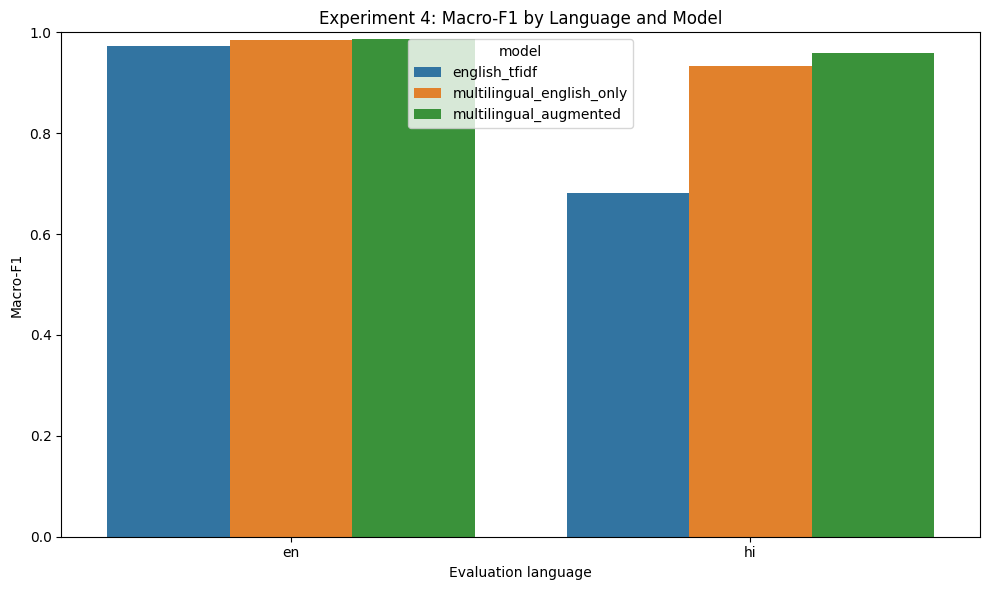

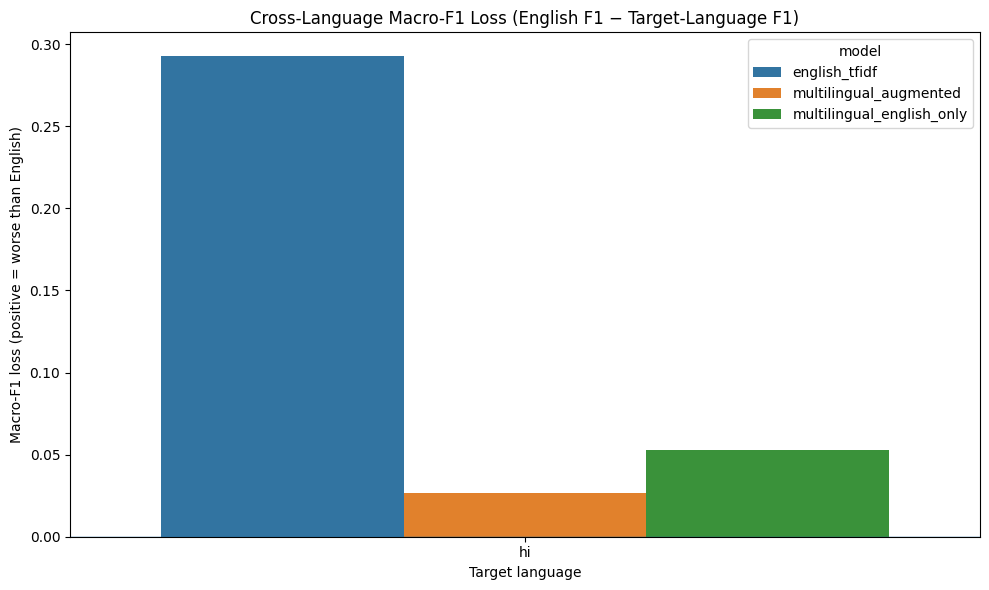

All outputs are in experiment4_results/


In [10]:
metrics_df = pd.DataFrame(all_results)
metrics_df.to_csv("experiment4_results/experiment4_metrics.csv", index=False)
pred_df = pd.DataFrame(predictions)
pred_df.to_csv("experiment4_results/experiment4_predictions.csv", index=False)

print("METRICS")
display(metrics_df.sort_values(["language","model"]))
print("Saved: experiment4_results/experiment4_metrics.csv")
print("Saved: experiment4_results/experiment4_predictions.csv")

# Chart 1: macro-F1 by language and model
if not metrics_df.empty:
    plt.figure(figsize=(10,6))
    sns.barplot(data=metrics_df, x="language", y="macro_f1", hue="model")
    plt.ylim(0,1)
    plt.title("Experiment 4: Macro-F1 by Language and Model")
    plt.xlabel("Evaluation language")
    plt.ylabel("Macro-F1")
    plt.tight_layout()
    plt.savefig("experiment4_results/macro_f1_by_language.png", dpi=200)
    plt.show()

# Chart 2: cross-language macro-F1 loss relative to English for each model.
pivot = metrics_df.pivot_table(index="model", columns="language", values="macro_f1", aggfunc="first")
loss_rows = []
if "en" in pivot.columns:
    for model_name, row in pivot.iterrows():
        en_score = row.get("en", np.nan)
        for lang in ["hi","hinglish"]:
            if lang in pivot.columns and pd.notna(en_score) and pd.notna(row.get(lang, np.nan)):
                loss_rows.append({
                    "model":model_name, "language":lang,
                    "english_macro_f1":en_score,
                    "language_macro_f1":row[lang],
                    "macro_f1_loss":en_score-row[lang]
                })
loss_df = pd.DataFrame(loss_rows)
loss_df.to_csv("experiment4_results/cross_language_performance_loss.csv", index=False)
if not loss_df.empty:
    plt.figure(figsize=(10,6))
    sns.barplot(data=loss_df, x="language", y="macro_f1_loss", hue="model")
    plt.axhline(0, linewidth=1)
    plt.title("Cross-Language Macro-F1 Loss (English F1 − Target-Language F1)")
    plt.xlabel("Target language")
    plt.ylabel("Macro-F1 loss (positive = worse than English)")
    plt.tight_layout()
    plt.savefig("experiment4_results/cross_language_loss.png", dpi=200)
    plt.show()

print("All outputs are in experiment4_results/")


In [11]:
import os
import shutil
from google.colab import files

results_folder = "/content/experiment4_results"
zip_path = "/content/experiment4_all_results.zip"

if not os.path.isdir(results_folder):
    raise FileNotFoundError(
        "experiment4_results folder not found. Run the experiment first."
    )

shutil.make_archive(
    "/content/experiment4_all_results",
    "zip",
    root_dir=results_folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


The `bolewara/hinglish-scam-text-dataset` card describes 3,787 total examples but only 35 hand-written Hinglish scam and 28 hand-written Hinglish benign messages. Its English rows partly derive from SMS Spam Collection. Treat the Hinglish subset as a small exploratory external test, not a definitive estimate. Do not mix it into the primary split unless you can identify and deduplicate overlapping English source messages.

```python
from datasets import load_dataset
hinglish_raw = load_dataset("bolewara/hinglish-scam-text-dataset")
print(hinglish_raw)
```

If loading fails, inspect the repository's files and README at:
https://huggingface.co/datasets/bolewara/hinglish-scam-text-dataset
